# Workshop 3 - Silver quality and distribution review

Team 9 - Kevin Rincon and Pablo Garzon.

We inspect saved successful Silver exports before designing Gold. Repeated
snapshots are observations of the same business records, not independent events.
No input is changed, and no network or database connection is used.
The acquisition covers 2021-2025 with one GHCN station. Course method conventions
remain to be checked against the exact classroom example; thresholds below are
explicit exploratory proposals, not instructor-mandated cleaning rules.

In [1]:
from pathlib import Path
import hashlib
import json
import math
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "workshop_2/evidence/historical_airflow_runs.json").exists())
out = root / "workshop_3/evidence"
out.mkdir(parents=True, exist_ok=True)
receipt_paths = [root / "workshop_2/evidence" / name for name in
                 ["historical_airflow_runs.json", "replay_airflow_runs.json"]]
files = {}
for path in receipt_paths:
    receipt = json.loads(path.read_text())
    for run in receipt["runs"]:
        assert run["bronze"]["state"] == run["silver"]["state"] == "success"
        export = run["output"]["silver"]
        files[export["path"]] = export
frames, hashes = [], {}
for name, export in sorted(files.items()):
    path = root / name
    digest = hashlib.sha256(path.read_bytes()).hexdigest().upper()
    assert digest == export["sha256"]
    df = pd.read_parquet(path)
    assert len(df) == export["rows"]
    df["export_path"] = name
    frames.append(df)
    hashes[name] = digest
raw = pd.concat(frames, ignore_index=True)
print("Verified exports:", len(files), "| Snapshot rows:", len(raw))
display(raw.head())

Verified exports: 13 | Snapshot rows: 22553


,record_id,source,source_key,event_type,observed_at_utc,observed_date,latitude,longitude,severity_value,severity_unit,magnitude_type,quality_attributes,source_content_sha256,capture_sha256,run_id,capture_id,source_line,revision_id,export_path
0,2670,ghcn_daily,USW00013967/2021-01-01/PRCP,PRCP,NaT,2021-01-01,35.38843,-97.60035,15.2,mm,NaN,",,W,2400",d774ca58c09fa9a69c146ce52b7079f404c8c96185b579...,3af94b20dfcb8276a79c6941a217569c9761470e790d39...,17,17,2,7455,data/curated/silver/ghcn_daily_20261117_020238...
1,2671,ghcn_daily,USW00013967/2021-01-01/TMAX,TMAX,NaT,2021-01-01,35.38843,-97.60035,1.1,degC,NaN,",,W",d774ca58c09fa9a69c146ce52b7079f404c8c96185b579...,3af94b20dfcb8276a79c6941a217569c9761470e790d39...,17,17,2,7456,data/curated/silver/ghcn_daily_20261117_020238...
2,2672,ghcn_daily,USW00013967/2021-01-01/TMIN,TMIN,NaT,2021-01-01,35.38843,-97.60035,-1.0,degC,NaN,",,W",d774ca58c09fa9a69c146ce52b7079f404c8c96185b579...,3af94b20dfcb8276a79c6941a217569c9761470e790d39...,17,17,2,7457,data/curated/silver/ghcn_daily_20261117_020238...
3,2673,ghcn_daily,USW00013967/2021-01-02/PRCP,PRCP,NaT,2021-01-02,35.38843,-97.60035,0.3,mm,NaN,",,W,2400",fbd850d836da22b057eddb8d0586b85425c26203de8a93...,3af94b20dfcb8276a79c6941a217569c9761470e790d39...,17,17,3,7458,data/curated/silver/ghcn_daily_20261117_020238...
4,2674,ghcn_daily,USW00013967/2021-01-02/TMAX,TMAX,NaT,2021-01-02,35.38843,-97.60035,5.6,degC,NaN,",,W",fbd850d836da22b057eddb8d0586b85425c26203de8a93...,3af94b20dfcb8276a79c6941a217569c9761470e790d39...,17,17,3,7459,data/curated/silver/ghcn_daily_20261117_020238...


## 1. Reconcile repeated exports

The recorded run ID orders successful runs within this local database history.
For each source/key we retain the latest observed snapshot by run ID. Before
selection, copies of the same key/revision must agree on content. This rule is
not a general ordering across independent databases. An older revision can be
observed again by a later run, so revision ID alone is not the selection rule.

In [2]:
keys = ["source", "source_key"]
conflicts = raw.groupby(keys + ["revision_id"])["source_content_sha256"].nunique()
assert not conflicts.gt(1).any(), "Conflicting snapshot lineage"
canonical = (raw.sort_values(["run_id", "export_path"])
             .drop_duplicates(keys, keep="last").copy())
assert not canonical.duplicated(keys).any()
inventory = raw.groupby("source").size().rename("snapshot_rows").to_frame()
inventory["business_records"] = canonical.groupby("source").size()
inventory["repeated_snapshot_rows"] = inventory["snapshot_rows"] - inventory["business_records"]
display(inventory)
display(canonical.groupby(["source", "event_type", "severity_unit"], dropna=False).size().to_frame("records"))

,snapshot_rows,business_records,repeated_snapshot_rows
source,,,
ghcn_daily,7668,5478,2190
noaa_storm_events,14885,13561,1324


records
source            event_type              severity_unit         
ghcn_daily        PRCP                    mm                1826
                  TMAX                    degC              1826
                  TMIN                    degC              1826
noaa_storm_events Blizzard                NaN                  2
                  Cold/Wind Chill         NaN                276
                  Dense Fog               NaN                  1
                  Drought                 NaN               1888
                  Dust Storm              NaN                  8
                  Excessive Heat          NaN               1499
                  Extreme Cold/Wind Chill NaN                118
                  Flash Flood             NaN                394
                  Flood                   NaN                129
                  Freezing Fog            NaN                  1
                  Frost/Freeze            NaN                 48
                  Funnel Cloud            NaN                  2
                  Hail                    in                2936
                  Heat                    NaN               2081
                  Heavy Rain              NaN                  1
                  Heavy Snow              NaN                159
                  High Wind               kn                 507
                  Ice Storm               NaN                  4
                  Lightning               NaN                 10
                  Sleet                   NaN                  3
                  Strong Wind             kn                   3
                  Thunderstorm Wind       kn                2492
                  Tornado                 NaN                513
                  Wildfire                NaN                203
                  Winter Storm            NaN                216
                  Winter Weather          NaN                 67

## 2. Missingness depends on record semantics

Daily GHCN records intentionally have no UTC instant. Missing storm points or
magnitudes are not filled with zeros. Compare null rates by source rather than
treating source-inapplicable columns as failed observations.

In [3]:
fields = ["observed_at_utc", "observed_date", "latitude", "longitude",
          "severity_value", "severity_unit", "quality_attributes"]
missing = canonical.groupby("source")[fields].agg(lambda s: s.isna().mean())
display(missing.rename_axis(columns="null fraction"))
daily = canonical[canonical["source"].eq("ghcn_daily")].copy()
daily["station"] = daily["source_key"].str.split("/").str[0]
daily["date"] = pd.to_datetime(daily["observed_date"])
assert daily["observed_at_utc"].isna().all()
assert daily["observed_date"].notna().all()
display(daily.groupby([daily["date"].dt.year, "event_type"])["severity_value"].count().unstack())
qc = daily["quality_attributes"].fillna("").str.split(",").str[1].fillna("")
display(qc.value_counts().rename_axis("Provider quality flag").to_frame("records"))

null fraction,observed_at_utc,observed_date,latitude,longitude,severity_value,severity_unit,quality_attributes
source,,,,,,,
ghcn_daily,1.0,0.0,0.00000,0.00000,0.000000,0.000000,0.0
noaa_storm_events,0.0,1.0,0.52238,0.52238,0.562127,0.562127,1.0


event_type,PRCP,TMAX,TMIN
date,,,
2021,365,365,365
2022,365,365,365
2023,365,365,365
2024,366,366,366
2025,365,365,365


,records
Provider quality flag,
,5478


## 3. Shape, IQR and Z-score

Pandas `skew()` uses bias-corrected sample skewness; `kurt()` reports sample
excess kurtosis (normal reference 0). Standard deviation uses ddof=1. Quantiles
use Pandas linear interpolation. Statistics are unavailable for insufficient or
constant samples rather than an invented zero. We compare 1.5-IQR fences with
absolute sample Z-score >3, without deleting any observation.

Do not select a method by which one flags fewer records. Skewed precipitation,
zero-heavy distributions and seasonal temperatures require different context.

In [4]:
def profile(values):
    values = values.dropna().astype(float)
    n = len(values)
    q1, q3 = values.quantile([0.25, 0.75]) if n else (float("nan"), float("nan"))
    iqr = q3 - q1
    sd = values.std(ddof=1) if n > 1 else float("nan")
    varying = n > 1 and values.nunique() > 1
    iqr_valid = pd.notna(iqr) and iqr > 0
    z_valid = pd.notna(sd) and sd > 0
    return {"n": n, "mean": values.mean(), "median": values.median(), "std_ddof1": sd,
            "q1": q1, "q3": q3, "iqr": iqr,
            "skewness": values.skew() if varying and n >= 3 else float("nan"),
            "excess_kurtosis": values.kurt() if varying and n >= 4 else float("nan"),
            "zero_fraction": values.eq(0).mean(),
            "iqr_lower": q1 - 1.5 * iqr, "iqr_upper": q3 + 1.5 * iqr,
            "iqr_flags": int(((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)).sum()) if iqr_valid else None,
            "zscore_flags": int(((values - values.mean()).abs() / sd > 3).sum()) if z_valid else None,
            "iqr_status": "review_only" if iqr_valid else "unavailable_zero_or_missing_iqr",
            "zscore_status": "comparison_only" if z_valid else "unavailable_zero_or_missing_std"}

profiles = []
for (station, element, unit), group in daily.groupby(["station", "event_type", "severity_unit"]):
    profiles.append({"station": station, "element": element, "unit": unit,
                     "population": "all_days", **profile(group["severity_value"])})
    if element == "PRCP":
        profiles.append({"station": station, "element": element, "unit": unit,
                         "population": "positive_reported_precipitation",
                         **profile(group.loc[group["severity_value"].gt(0), "severity_value"])})
summary = pd.DataFrame(profiles)
display(summary)
assert profile(pd.Series([1., 1., 1., 1.]))["iqr_flags"] is None
assert math.isnan(profile(pd.Series([1., 2.]))["skewness"])
assert profile(pd.Series([0., 1., 2., 3.]))["iqr_flags"] == 0

,station,element,unit,population,n,mean,median,std_ddof1,q1,q3,iqr,skewness,excess_kurtosis,zero_fraction,iqr_lower,iqr_upper,iqr_flags,zscore_flags,iqr_status,zscore_status
0,USW00013967,PRCP,mm,all_days,1826,2.395235,0.0,8.709749,0.00,0.0,0.00,7.296155,89.637273,0.786418,0.000,0.000,NaN,46,unavailable_zero_or_missing_iqr,comparison_only
1,USW00013967,PRCP,mm,positive_reported_precipitation,390,11.214615,5.1,16.023013,1.30,15.5,14.20,3.704699,25.204027,0.000000,-20.000,36.800,25.0,6,review_only,comparison_only
2,USW00013967,TMAX,degC,all_days,1826,22.946495,24.4,10.083521,16.10,31.1,15.00,-0.617717,-0.058923,0.003286,-6.400,53.600,14.0,9,review_only,comparison_only
3,USW00013967,TMIN,degC,all_days,1826,10.171413,11.1,9.747820,2.35,18.9,16.55,-0.420144,-0.713884,0.021358,-22.475,43.725,1.0,2,review_only,comparison_only


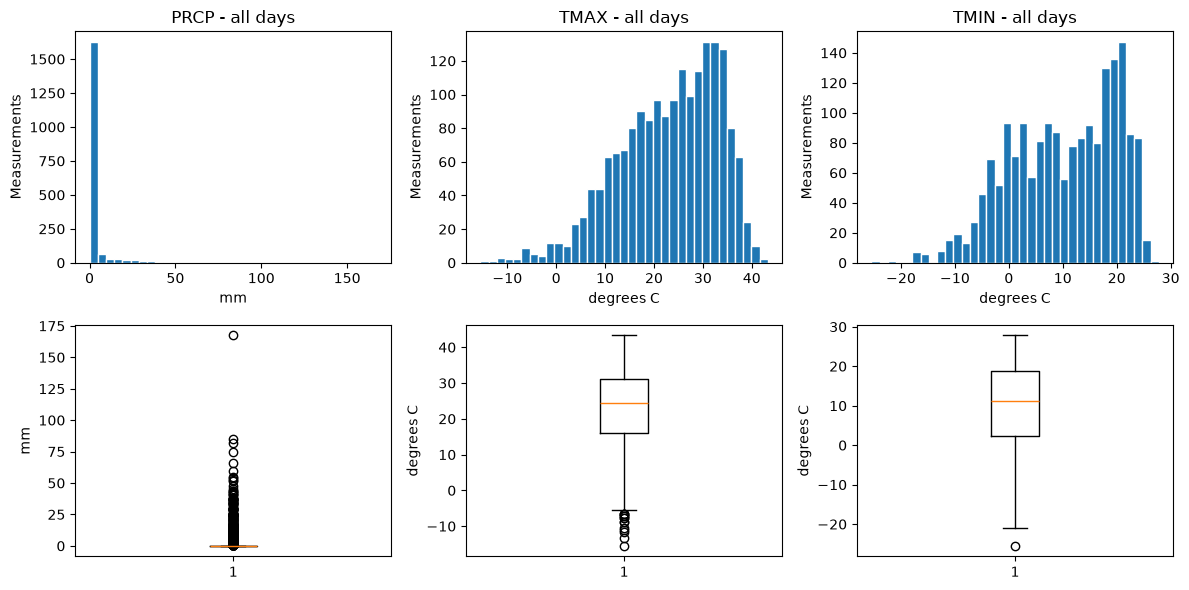

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for col, element in enumerate(["PRCP", "TMAX", "TMIN"]):
    values = daily.loc[daily["event_type"].eq(element), "severity_value"].dropna()
    unit = "mm" if element == "PRCP" else "degrees C"
    axes[0, col].hist(values, bins=35, edgecolor="white")
    axes[0, col].set_title(element + " - all days")
    axes[0, col].set_xlabel(unit)
    axes[0, col].set_ylabel("Measurements")
    axes[1, col].boxplot(values)
    axes[1, col].set_ylabel(unit)
plt.tight_layout()
plt.show()

## 4. Seasonality and precipitation populations

Positive reported precipitation means PRCP >0 mm, not a validated climatological
wet-day threshold; provider trace flags remain in the input attributes. Both
the full daily series and the positive subset are reported. Month-specific
temperature summaries help identify the limits of pooled-year flags.

,station,element,month,n,median,skewness,excess_kurtosis,iqr_flags,zscore_flags
0,USW00013967,PRCP,1,155,0.0,3.632084,13.198107,NaN,5
1,USW00013967,PRCP,2,141,0.0,3.926136,17.330183,NaN,3
2,USW00013967,PRCP,3,155,0.0,4.531225,21.948888,NaN,6
3,USW00013967,PRCP,4,150,0.0,3.155880,10.495471,31.0,5
4,USW00013967,PRCP,5,155,0.0,2.755410,7.395005,30.0,6
5,USW00013967,PRCP,6,150,0.0,3.715042,15.456511,33.0,3
6,USW00013967,PRCP,7,155,0.0,5.036895,30.384316,NaN,5
7,USW00013967,PRCP,8,155,0.0,10.032031,113.070719,NaN,1
8,USW00013967,PRCP,9,150,0.0,6.704018,48.963013,NaN,3
9,USW00013967,PRCP,10,155,0.0,3.794087,14.143838,NaN,7


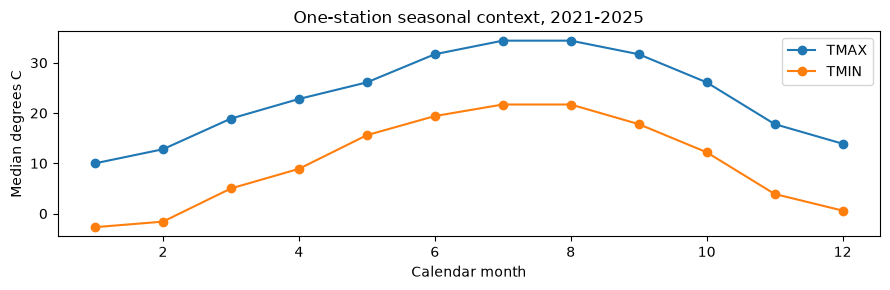

In [6]:
seasonal = []
for (station, element, month), group in daily.groupby(["station", "event_type", daily["date"].dt.month]):
    seasonal.append({"station": station, "element": element, "month": month, **profile(group["severity_value"])})
seasonal = pd.DataFrame(seasonal)
display(seasonal[["station", "element", "month", "n", "median", "skewness", "excess_kurtosis", "iqr_flags", "zscore_flags"]])
fig, ax = plt.subplots(figsize=(9, 3))
for element in ["TMAX", "TMIN"]:
    series = daily[daily["event_type"].eq(element)].groupby(daily["date"].dt.month)["severity_value"].median()
    ax.plot(series.index, series.values, marker="o", label=element)
ax.set(xlabel="Calendar month", ylabel="Median degrees C", title="One-station seasonal context, 2021-2025")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Decisions and Gold/dashboard handoff

Keep all statistical extremes. Use IQR as the first descriptive review for
skewed variables with a nonzero IQR, and show Z-score as a comparison rather
than a normality claim. When IQR is zero, report it as unavailable; do not
silently flag every positive rainfall value. Keep precipitation populations and
monthly temperature context separate. Thresholds remain exploratory and subject
to course-example review; no automatic curation rule is promoted here.

Gold governance should expose source-specific missingness, coverage, repeated
snapshot counts versus unique keys and method-labelled review flags. Storytelling
should support event counts over time and station-specific weather distributions.
Exploratory associations do not establish causes. These are descriptive and
exploratory diagnostic views, not forecasts or prescriptive safety advice.
PySpark Gold, its DAG and incremental integration are not implemented by this notebook.

## 7. Narrative quality and lexical tone

The registered NOAA Oklahoma 2021 source supplies event or episode narratives.
We retain original text and source identity, and score original English text with
VADER 3.3.2. The score describes lexical tone, not hazard severity. Other years
have no portable text Silver in this delivery; no labelled validation exists.

,text_field,characters,sentiment_score,sentiment_label
count,1324,1324.000000,1324.000000,1324
unique,2,NaN,NaN,3
top,EPISODE_NARRATIVE,NaN,NaN,neutral
freq,692,NaN,NaN,456
mean,NaN,280.526435,0.011959,NaN
std,NaN,307.761091,0.450719,NaN
min,NaN,13.000000,-0.990700,NaN
25%,NaN,102.750000,-0.318200,NaN
50%,NaN,177.000000,0.000000,NaN
75%,NaN,336.000000,0.421500,NaN


sentiment_label
negative    423
neutral     456
positive    445
Name: records, dtype: int64

,keyword,mentions
0,th,895
1,oklahoma,812
2,wind,595
3,drought,444
4,county,394
5,reported,350
6,hail,346
7,afternoon,345
8,developed,339
9,thunderstorms,327


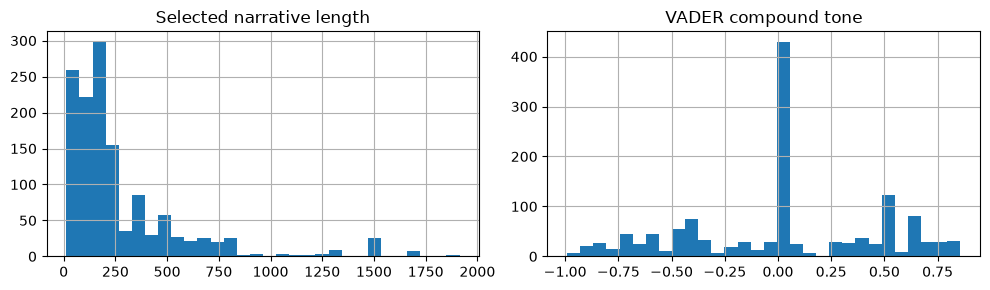

In [7]:
text_manifest = json.loads((root / "workshop_3/samples/silver_text/noaa_oklahoma_2021_text.manifest.json").read_text())
text_path = root / text_manifest["path"]
assert hashlib.sha256(text_path.read_bytes()).hexdigest().upper() == text_manifest["sha256"]
texts = pd.read_parquet(text_path)
assert len(texts) == text_manifest["rows"] == 1324
assert texts.source_key.is_unique and texts.raw_text.notna().all()
display(texts[["text_field", "characters", "sentiment_score", "sentiment_label"]].describe(include="all"))
display(texts.groupby("sentiment_label").size().rename("records"))
from collections import Counter
display(pd.DataFrame(Counter(t for tokens in texts.tokens for t in tokens).most_common(12), columns=["keyword", "mentions"]))
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
texts.characters.hist(bins=30, ax=axes[0]); axes[0].set_title("Selected narrative length")
texts.sentiment_score.hist(bins=30, ax=axes[1]); axes[1].set_title("VADER compound tone")
plt.tight_layout(); plt.show()

In [8]:
summary.to_csv(out / "distribution_review.csv", index=False)
seasonal.to_csv(out / "seasonal_review.csv", index=False)
inventory.to_csv(out / "snapshot_inventory.csv")
missing.to_csv(out / "source_missingness.csv")
audit = {"input_sha256": hashes, "verified_exports": len(files),
         "snapshot_rows": len(raw), "unique_business_records": len(canonical),
         "repeated_snapshot_rows": len(raw) - len(canonical),
         "source_counts": {str(k): int(v) for k, v in canonical.groupby("source").size().items()},
         "weather_requests": False, "raw_values_changed": False,
         "selection_rule": "Latest observed successful local run_id per source/key; tie by export path after content consistency check",
         "methods": {"skewness": "pandas bias-corrected sample skew", "kurtosis": "pandas sample excess kurtosis; normal reference zero",
                     "iqr_multiplier": 1.5, "zscore_threshold": 3, "std_ddof": 1,
                     "policy": "Review flags only; no deletion or imputation"}}
(out / "silver_review.json").write_text(json.dumps(audit, indent=2) + "\n")
print("Saved evidence:", out)
print("Unique business records:", len(canonical))

Saved evidence: C:\Users\orlag_nzyjv2m\Downloads\multi-hazard-weather-monitoring\workshop_3\evidence
Unique business records: 19039
